In [1]:
import pandas as pd 
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import classification_report 
import matplotlib.pyplot as plt
import joblib
import seaborn as sns


In [2]:
data=pd.read_csv('data/upi_bank_grade_data.csv')

In [3]:
x=data.drop('fraud',axis=1)
y=data['fraud']

In [4]:
X_train,X_test,Y_train,Y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [5]:
randomforestmodel=RandomForestClassifier(
    n_estimators=300,
    max_depth=40,  
)
randomforestmodel.fit(X_train,Y_train)
pred=randomforestmodel.predict(X_test)
print(classification_report(Y_test,pred))

              precision    recall  f1-score   support

           0       0.87      0.90      0.88      6026
           1       0.84      0.79      0.81      3974

    accuracy                           0.86     10000
   macro avg       0.85      0.85      0.85     10000
weighted avg       0.86      0.86      0.86     10000



In [6]:
gradientboostingmodel=GradientBoostingClassifier(
    n_estimators=300,
    max_depth=40,  
)
gradientboostingmodel.fit(X_train,Y_train)
pred1=gradientboostingmodel.predict(X_test)
print(classification_report(Y_test,pred1))

              precision    recall  f1-score   support

           0       0.83      0.85      0.84      6026
           1       0.76      0.74      0.75      3974

    accuracy                           0.80     10000
   macro avg       0.80      0.79      0.79     10000
weighted avg       0.80      0.80      0.80     10000



In [7]:
lgbmmodel=LGBMClassifier(
    n_estimators=300,
    max_depth=40,  
)
lgbmmodel.fit(X_train,Y_train)
pred2=lgbmmodel.predict(X_test)
print(classification_report(Y_test,pred2))

[LightGBM] [Info] Number of positive: 15764, number of negative: 24236
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002299 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 829
[LightGBM] [Info] Number of data points in the train set: 40000, number of used features: 17
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.394100 -> initscore=-0.430110
[LightGBM] [Info] Start training from score -0.430110
              precision    recall  f1-score   support

           0       0.89      0.90      0.90      6026
           1       0.85      0.84      0.84      3974

    accuracy                           0.88     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.88      0.88      0.88     10000



In [8]:
ensemble_model=VotingClassifier(
    estimators=[
        ('rf', randomforestmodel),
        ('gb', gradientboostingmodel),
        ('lgbm', lgbmmodel)
    ],
    voting='soft'
)
ensemble_model.fit(X_train,Y_train)
pred_final=ensemble_model.predict(X_test)
print(classification_report(Y_test,pred_final))

[LightGBM] [Info] Number of positive: 15764, number of negative: 24236
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001411 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 829
[LightGBM] [Info] Number of data points in the train set: 40000, number of used features: 17
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.394100 -> initscore=-0.430110
[LightGBM] [Info] Start training from score -0.430110
              precision    recall  f1-score   support

           0       0.86      0.88      0.87      6026
           1       0.82      0.78      0.80      3974

    accuracy                           0.84     10000
   macro avg       0.84      0.83      0.84     10000
weighted avg       0.84      0.84      0.84     10000



In [9]:
joblib.dump(ensemble_model,'models/final_model.pkl')
print("Model saved successfully!")
joblib.dump(randomforestmodel,'models/random_forest_model.pkl')
print("Random Forest model saved successfully!")
joblib.dump(gradientboostingmodel,'models/gradient_boosting_model.pkl')
print("Gradient Boosting model saved successfully!")
joblib.dump(lgbmmodel,'models/lgbm_model.pkl')
print("LightGBM model saved successfully!")

Model saved successfully!
Random Forest model saved successfully!
Gradient Boosting model saved successfully!
LightGBM model saved successfully!


In [10]:
models={
    "Random Forest": randomforestmodel,
    "Gradient Boosting": gradientboostingmodel,
    "LightGBM": lgbmmodel,
    "Ensemble": ensemble_model
}
result=[]


In [11]:
for name,model in models.items():
    pred=model.predict(X_test)
    report=classification_report(Y_test,pred,output_dict=True)
    result.append({
        "Model": name,
        "Precision": report['weighted avg']['precision'],
        "Recall": report['weighted avg']['recall'],
        "F1-Score": report['weighted avg']['f1-score']
    })


In [12]:
df=pd.DataFrame(result)
print(df)

               Model  Precision  Recall  F1-Score
0      Random Forest   0.857026  0.8576  0.856656
1  Gradient Boosting   0.802403  0.8033  0.802709
2           LightGBM   0.876085  0.8763  0.876172
3           Ensemble   0.843275  0.8440  0.843396


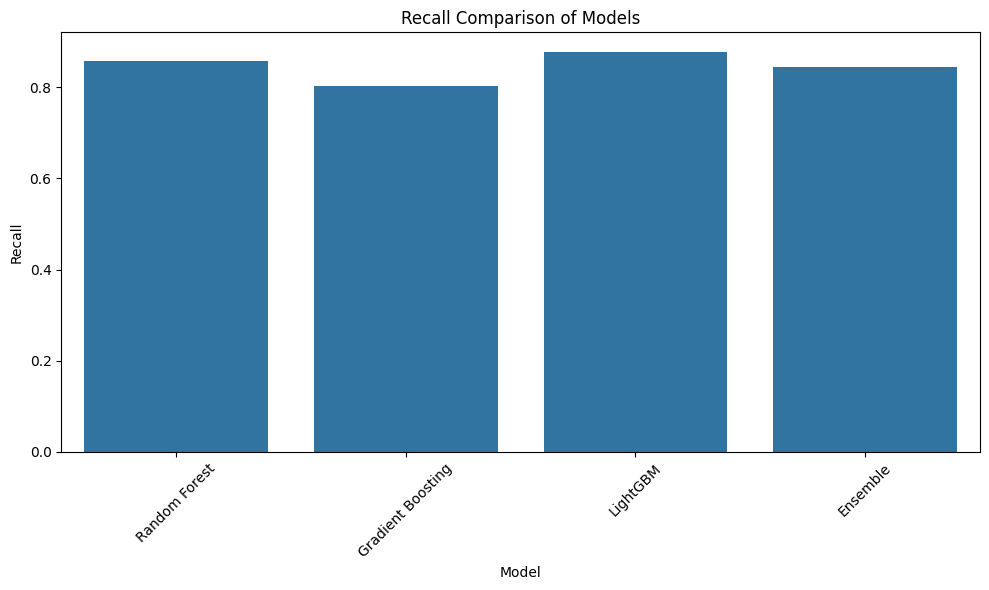

In [13]:
plt.figure(figsize=(10,6))
sns.barplot(x="Model", y="Recall", data=df)
plt.xticks(rotation=45)
plt.title("Recall Comparison of Models")
plt.tight_layout()
plt.show()